# College Canteen Crowd Prediction — First ML Classification Class

**Goal:** Predict whether the canteen will be crowded (`Yes`) or not crowded (`No`) from simple details.

> **Important data note:** This is a realistic-looking **practice dataset generated for teaching**. It is not collected from a real college canteen and must not be presented as actual operational records. For a real deployment, replace it with dated canteen observations / token counts / sales records. The input patterns are designed to be plausible for a classroom exercise.

**Beginner-friendly rules**
- No one-hot encoding.
- No manual/hard-coded category-to-number mapping.
- We use `LabelEncoder` to convert text categories into numbers so scikit-learn algorithms can work.
- Each algorithm is trained separately, with a separate code cell.
- This is a learning demonstration, not a production crowd forecasting system.

## 1. Import the required libraries
We use pandas for tables, matplotlib for simple charts, and scikit-learn for machine learning.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import CategoricalNB

## 2. Load the dataset
Keep the CSV file in the same folder as this notebook.

In [2]:
df = pd.read_csv("college_canteen_crowd_dataset.csv")
df.head()

,Food_Type,Food_Name,Shift,Is_Event_Day,Is_Weekend,Weather,Has_Discount_or_Offer,Crowd_Present
0,Meal,Chole Rice,Evening,No,No,Sunny,No,No
1,Snacks,Puff,Evening,Yes,No,Cloudy,No,No
2,Meal,Veg Thali,Evening,No,No,Sunny,No,No
3,Snacks,Puff,Evening,No,No,Cold/Winter,No,Yes
4,Snacks,Puff,Morning,Yes,No,Hot/Summer,No,Yes


## 3. Understand the data (EDA)
EDA means Exploratory Data Analysis. It means looking at the data before training a model.

In [3]:
print("Rows and columns:", df.shape)
print("\\nColumn names:")
print(df.columns.tolist())
print("\\nData types:")
print(df.dtypes)
print("\\nMissing values in each column:")
print(df.isnull().sum())
print("\\nBasic summary of text columns:")
display(df.describe(include="all"))

Rows and columns: (360, 8)
\nColumn names:
['Food_Type', 'Food_Name', 'Shift', 'Is_Event_Day', 'Is_Weekend', 'Weather', 'Has_Discount_or_Offer', 'Crowd_Present']
\nData types:
Food_Type                object
Food_Name                object
Shift                    object
Is_Event_Day             object
Is_Weekend               object
Weather                  object
Has_Discount_or_Offer    object
Crowd_Present            object
dtype: object
\nMissing values in each column:
Food_Type                0
Food_Name                0
Shift                    0
Is_Event_Day             0
Is_Weekend               0
Weather                  0
Has_Discount_or_Offer    0
Crowd_Present            0
dtype: int64
\nBasic summary of text columns:


,Food_Type,Food_Name,Shift,Is_Event_Day,Is_Weekend,Weather,Has_Discount_or_Offer,Crowd_Present
count,360,360,360,360,360,360,360,360
unique,4,16,2,2,2,5,2,2
top,Snacks,Veg Thali,Morning,No,No,Sunny,No,Yes
freq,108,30,210,301,250,84,262,194


In [4]:
# Check whether any complete row is repeated
print("Duplicate rows:", df.duplicated().sum())

# Check the target variable: Yes / No
print(df["Crowd_Present"].value_counts())
print("\\nTarget percentage:")
print((df["Crowd_Present"].value_counts(normalize=True) * 100).round(1))

Duplicate rows: 45
Crowd_Present
Yes    194
No     166
Name: count, dtype: int64
\nTarget percentage:
Crowd_Present
Yes    53.9
No     46.1
Name: proportion, dtype: float64


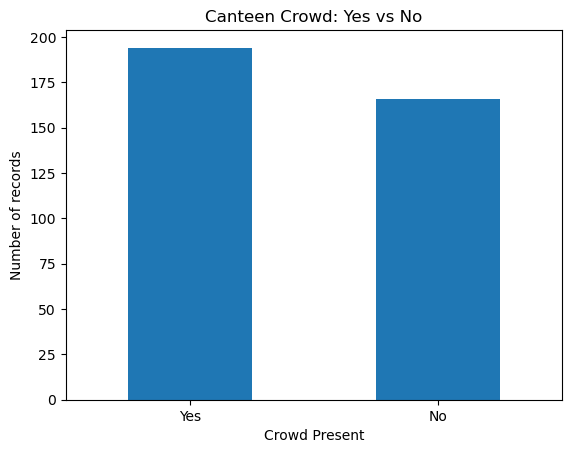

In [5]:
# Simple chart: how many Yes and No examples are present?
df["Crowd_Present"].value_counts().plot(kind="bar", rot=0)
plt.title("Canteen Crowd: Yes vs No")
plt.xlabel("Crowd Present")
plt.ylabel("Number of records")
plt.show()

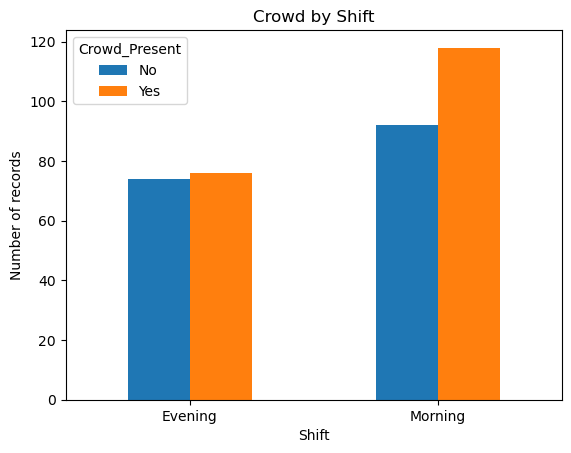

In [6]:
# Explore crowd presence by shift
pd.crosstab(df["Shift"], df["Crowd_Present"]).plot(kind="bar")
plt.title("Crowd by Shift")
plt.xlabel("Shift")
plt.ylabel("Number of records")
plt.xticks(rotation=0)
plt.show()

## 4. Separate input columns (X) and target column (y)

- **X:** Information given to the model (food type, food name, shift, event, weekend, weather, offer).
- **y:** The answer we want the model to predict (`Crowd_Present`: Yes or No).

In [7]:
X = df.drop("Crowd_Present", axis=1)
y = df["Crowd_Present"]

print("Input columns:")
print(X.head())
print("\\nTarget:")
print(y.head())

Input columns:
  Food_Type   Food_Name    Shift Is_Event_Day Is_Weekend      Weather  \
0      Meal  Chole Rice  Evening           No         No        Sunny   
1    Snacks        Puff  Evening          Yes         No       Cloudy   
2      Meal   Veg Thali  Evening           No         No        Sunny   
3    Snacks        Puff  Evening           No         No  Cold/Winter   
4    Snacks        Puff  Morning          Yes         No   Hot/Summer   

  Has_Discount_or_Offer  
0                    No  
1                    No  
2                    No  
3                    No  
4                    No  
\nTarget:
0     No
1     No
2     No
3    Yes
4    Yes
Name: Crowd_Present, dtype: object


## 5. Convert text into numbers (without One-Hot Encoding)

Machine learning algorithms need numeric input. We use `LabelEncoder` separately for each input column. It assigns a number to each category automatically; we are **not** writing category numbers by hand.

**Simple caution:** Label encoding gives categories numeric labels. For categories such as weather or food name, those numbers do not mean that one category is greater than another. This is acceptable for this introductory comparison, especially for tree-based models, but it can affect distance/linear algorithms. Later, students can learn better ways to represent categories.

In [8]:
X_encoded = X.copy()
feature_encoders = {}

for column in X.columns:
    encoder = LabelEncoder()
    X_encoded[column] = encoder.fit_transform(X[column])
    feature_encoders[column] = encoder

target_encoder = LabelEncoder()
y_encoded = target_encoder.fit_transform(y)

print("Text data converted into numeric labels.")
print(X_encoded.head())
print("Target classes:", list(target_encoder.classes_))

Text data converted into numeric labels.
   Food_Type  Food_Name  Shift  Is_Event_Day  Is_Weekend  Weather  \
0          2          1      0             0           0        4   
1          3          9      0             1           0        0   
2          2         15      0             0           0        4   
3          3          9      0             0           0        1   
4          3          9      1             1           0        2   

   Has_Discount_or_Offer  
0                      0  
1                      0  
2                      0  
3                      0  
4                      0  
Target classes: ['No', 'Yes']


## 6. Split the data into training and testing parts

The model learns from the training data. We use the testing data to check how it performs on records it did not train on.

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y_encoded,
    test_size=0.20,
    random_state=42,
    stratify=y_encoded
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 288
Testing records: 72


## 7. Algorithm 1 — Decision Tree

A Decision Tree makes decisions by asking simple questions, like a flowchart.

In [10]:
decision_tree = DecisionTreeClassifier(max_depth=5, random_state=42)
decision_tree.fit(X_train, y_train)

dt_predictions = decision_tree.predict(X_test)

print("Decision Tree Accuracy:", round(accuracy_score(y_test, dt_predictions) * 100, 2), "%")
print("\\nConfusion Matrix:")
print(confusion_matrix(y_test, dt_predictions))
print("\\nClassification Report:")
print(classification_report(y_test, dt_predictions, target_names=target_encoder.classes_))

Decision Tree Accuracy: 47.22 %
\nConfusion Matrix:
[[23 10]
 [28 11]]
\nClassification Report:
              precision    recall  f1-score   support

          No       0.45      0.70      0.55        33
         Yes       0.52      0.28      0.37        39

    accuracy                           0.47        72
   macro avg       0.49      0.49      0.46        72
weighted avg       0.49      0.47      0.45        72



## 8. Algorithm 2 — Random Forest

Random Forest combines multiple decision trees. Each tree gives a prediction, and the forest combines their answers.

In [11]:
random_forest = RandomForestClassifier(n_estimators=100, max_depth=6, random_state=42)
random_forest.fit(X_train, y_train)

rf_predictions = random_forest.predict(X_test)

print("Random Forest Accuracy:", round(accuracy_score(y_test, rf_predictions) * 100, 2), "%")
print("\\nConfusion Matrix:")
print(confusion_matrix(y_test, rf_predictions))
print("\\nClassification Report:")
print(classification_report(y_test, rf_predictions, target_names=target_encoder.classes_))

Random Forest Accuracy: 59.72 %
\nConfusion Matrix:
[[21 12]
 [17 22]]
\nClassification Report:
              precision    recall  f1-score   support

          No       0.55      0.64      0.59        33
         Yes       0.65      0.56      0.60        39

    accuracy                           0.60        72
   macro avg       0.60      0.60      0.60        72
weighted avg       0.60      0.60      0.60        72



## 9. Algorithm 3 — K-Nearest Neighbors (KNN)

KNN looks at the most similar examples in the training data and predicts the most common answer among nearby examples. We scale the values before using KNN.

In [12]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_scaled, y_train)

knn_predictions = knn.predict(X_test_scaled)

print("KNN Accuracy:", round(accuracy_score(y_test, knn_predictions) * 100, 2), "%")
print("\\nConfusion Matrix:")
print(confusion_matrix(y_test, knn_predictions))
print("\\nClassification Report:")
print(classification_report(y_test, knn_predictions, target_names=target_encoder.classes_))

KNN Accuracy: 55.56 %
\nConfusion Matrix:
[[14 19]
 [13 26]]
\nClassification Report:
              precision    recall  f1-score   support

          No       0.52      0.42      0.47        33
         Yes       0.58      0.67      0.62        39

    accuracy                           0.56        72
   macro avg       0.55      0.55      0.54        72
weighted avg       0.55      0.56      0.55        72



## 10. Algorithm 4 — Logistic Regression

Logistic Regression is a classification algorithm. It estimates the probability of each class and selects a class. Scaling is used here to help the model.

In [13]:
logistic_model = LogisticRegression(max_iter=1000, random_state=42)
logistic_model.fit(X_train_scaled, y_train)

lr_predictions = logistic_model.predict(X_test_scaled)

print("Logistic Regression Accuracy:", round(accuracy_score(y_test, lr_predictions) * 100, 2), "%")
print("\\nConfusion Matrix:")
print(confusion_matrix(y_test, lr_predictions))
print("\\nClassification Report:")
print(classification_report(y_test, lr_predictions, target_names=target_encoder.classes_))

Logistic Regression Accuracy: 65.28 %
\nConfusion Matrix:
[[19 14]
 [11 28]]
\nClassification Report:
              precision    recall  f1-score   support

          No       0.63      0.58      0.60        33
         Yes       0.67      0.72      0.69        39

    accuracy                           0.65        72
   macro avg       0.65      0.65      0.65        72
weighted avg       0.65      0.65      0.65        72



## 11. Algorithm 5 — Categorical Naive Bayes

Naive Bayes uses probabilities. `CategoricalNB` is designed for category-like integer inputs, so we use the encoded (unscaled) data.

In [14]:
category_counts = [len(feature_encoders[column].classes_) for column in X.columns]
naive_bayes = CategoricalNB(min_categories=category_counts)
naive_bayes.fit(X_train, y_train)

nb_predictions = naive_bayes.predict(X_test)

print("Categorical Naive Bayes Accuracy:", round(accuracy_score(y_test, nb_predictions) * 100, 2), "%")
print("\\nConfusion Matrix:")
print(confusion_matrix(y_test, nb_predictions))
print("\\nClassification Report:")
print(classification_report(y_test, nb_predictions, target_names=target_encoder.classes_))

Categorical Naive Bayes Accuracy: 62.5 %
\nConfusion Matrix:
[[22 11]
 [16 23]]
\nClassification Report:
              precision    recall  f1-score   support

          No       0.58      0.67      0.62        33
         Yes       0.68      0.59      0.63        39

    accuracy                           0.62        72
   macro avg       0.63      0.63      0.62        72
weighted avg       0.63      0.62      0.63        72



## 12. Compare the algorithms

Accuracy tells us the percentage of test examples predicted correctly. Do not choose a model only because its accuracy is highest; also inspect the confusion matrix and class-wise precision/recall.

In [15]:
results = pd.DataFrame({
    "Algorithm": ["Decision Tree", "Random Forest", "KNN", "Logistic Regression", "Categorical Naive Bayes"],
    "Accuracy (%)": [
        accuracy_score(y_test, dt_predictions) * 100,
        accuracy_score(y_test, rf_predictions) * 100,
        accuracy_score(y_test, knn_predictions) * 100,
        accuracy_score(y_test, lr_predictions) * 100,
        accuracy_score(y_test, nb_predictions) * 100
    ]
}).sort_values("Accuracy (%)", ascending=False)

results["Accuracy (%)"] = results["Accuracy (%)"].round(2)
results

,Algorithm,Accuracy (%)
3,Logistic Regression,65.28
4,Categorical Naive Bayes,62.50
1,Random Forest,59.72
2,KNN,55.56
0,Decision Tree,47.22


## 13. Try one new canteen situation

Change the values below to a combination you want to test. The model uses the same category encoders created from the training dataset.

In [16]:
new_record = pd.DataFrame([{
    "Food_Type": "Snacks",
    "Food_Name": "Samosa",
    "Shift": "Evening",
    "Is_Event_Day": "Yes",
    "Is_Weekend": "No",
    "Weather": "Rainy",
    "Has_Discount_or_Offer": "Yes"
}])

# Convert each text value using the encoder fitted earlier
new_record_encoded = new_record.copy()
for column in new_record.columns:
    new_record_encoded[column] = feature_encoders[column].transform(new_record[column])

# Use the Random Forest model for this demonstration
prediction_number = random_forest.predict(new_record_encoded)[0]
prediction = target_encoder.inverse_transform([prediction_number])[0]

print("Predicted crowd status:", prediction)

Predicted crowd status: Yes


## 14. What students should remember

1. **Dataset:** A table containing examples.
2. **Feature / input (X):** The information used for prediction.
3. **Target (y):** The answer the model learns to predict.
4. **EDA:** Understanding the dataset using counts, summaries and charts.
5. **Training:** Teaching the model using known examples.
6. **Testing:** Checking predictions on unseen examples.
7. **Classification:** Predicting a category such as `Yes` or `No`.
8. **Accuracy:** The percentage of correct predictions.

**Important for a real college canteen:** Record actual observations over several weeks. Define “crowded” consistently (for example, more than a chosen number of people present at a fixed observation time). Add a date/time and actual headcount in the data collection sheet, then derive the Yes/No target from the college's agreed threshold. Do not use this practice dataset to make real staffing or purchasing decisions.